In [1]:
import kagglehub
import os
import tensorflow as tf

BASE = kagglehub.dataset_download("kmader/skin-cancer-mnist-ham10000")
print(BASE)
print(os.listdir(BASE))
print(tf.config.list_physical_devices("GPU"))

Using Colab cache for faster access to the 'skin-cancer-mnist-ham10000' dataset.
/kaggle/input/skin-cancer-mnist-ham10000
['hmnist_8_8_RGB.csv', 'hmnist_28_28_RGB.csv', 'HAM10000_images_part_1', 'ham10000_images_part_1', 'hmnist_8_8_L.csv', 'HAM10000_images_part_2', 'ham10000_images_part_2', 'hmnist_28_28_L.csv', 'HAM10000_metadata.csv']
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.utils.class_weight import compute_class_weight

df = pd.read_csv(f"{BASE}/HAM10000_metadata.csv")

paths = {}
for part in ["HAM10000_images_part_1", "HAM10000_images_part_2"]:
    d = f"{BASE}/{part}"
    for f in os.listdir(d):
        paths[f.replace(".jpg", "")] = f"{d}/{f}"
df["path"] = df["image_id"].map(paths)

def split(data, n_splits, seed=42):
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    rest, part = next(sgkf.split(data, data["dx"], groups=data["lesion_id"]))
    return data.iloc[rest], data.iloc[part]

train_val, test = split(df, 10)
train, val = split(train_val, 9)
print(len(train), len(val), len(test))

CLASSES = sorted(df["dx"].unique())
label_to_idx = {c: i for i, c in enumerate(CLASSES)}
IMG_SIZE = 128
BATCH = 32

def make_ds(data, training):
    x = data["path"].values
    y = data["dx"].map(label_to_idx).values
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    if training:
        ds = ds.shuffle(len(data), seed=42)

    def load(path, label):
        img = tf.io.read_file(path)
        img = tf.image.decode_jpeg(img, channels=3)
        img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
        return img, label

    ds = ds.map(load, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(train, True)
val_ds = make_ds(val, False)
test_ds = make_ds(test, False)

weights = compute_class_weight(
    "balanced", classes=np.arange(len(CLASSES)), y=train["dx"].map(label_to_idx)
)
class_weight = dict(enumerate(weights))

print(CLASSES)
print({CLASSES[i]: round(w, 2) for i, w in class_weight.items()})

images, labels = next(iter(train_ds))
print(images.shape, labels.shape)

8013 1010 992
['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
{'akiec': np.float64(4.69), 'bcc': np.float64(2.88), 'bkl': np.float64(1.3), 'df': np.float64(12.18), 'mel': np.float64(1.3), 'nv': np.float64(0.21), 'vasc': np.float64(9.7)}
(32, 128, 128, 3) (32,)


In [3]:
from tensorflow import keras
from tensorflow.keras import layers

augmentation = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
], name="augmentation")

def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    return layers.MaxPooling2D()(x)

inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = augmentation(inputs)
x = layers.Rescaling(1.0 / 255)(x)
for f in (32, 64, 128, 256):
    x = conv_block(x, f)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(len(CLASSES), activation="softmax")(x)

model = keras.Model(inputs, outputs, name="cnn_scratch")
model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()

Model: "cnn_scratch"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 7)              │         1,799 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 391,655 (1.49 MB)

 Trainable params: 390,695 (1.49 MB)

 Non-trainable params: 960 (3.75 KB)

In [4]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3),
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    class_weight=class_weight,
    callbacks=callbacks,
)

Epoch 1/30
251/251 ━━━━━━━━━━━━━━━━━━━━ 69s 233ms/step - accuracy: 0.3969 - loss: 1.7571 - val_accuracy: 0.0515 - val_loss: 1.8641 - learning_rate: 0.0010
Epoch 2/30
251/251 ━━━━━━━━━━━━━━━━━━━━ 41s 164ms/step - accuracy: 0.4503 - loss: 1.5466 - val_accuracy: 0.5178 - val_loss: 1.3457 - learning_rate: 0.0010
Epoch 3/30
251/251 ━━━━━━━━━━━━━━━━━━━━ 45s 179ms/step - accuracy: 0.4631 - loss: 1.4646 - val_accuracy: 0.5941 - val_loss: 1.1649 - learning_rate: 0.0010
Epoch 4/30
251/251 ━━━━━━━━━━━━━━━━━━━━ 40s 158ms/step - accuracy: 0.4770 - loss: 1.4160 - val_accuracy: 0.3475 - val_loss: 1.9414 - learning_rate: 0.0010
Epoch 5/30
251/251 ━━━━━━━━━━━━━━━━━━━━ 40s 160ms/step - accuracy: 0.4893 - loss: 1.3766 - val_accuracy: 0.3970 - val_loss: 1.7729 - learning_rate: 0.0010
Epoch 6/30
251/251 ━━━━━━━━━━━━━━━━━━━━ 41s 159ms/step - accuracy: 0.4929 - loss: 1.3793 - val_accuracy: 0.4743 - val_loss: 1.3017 - learning_rate: 0.0010
Epoch 7/30
251/251 ━━━━━━━━━━━━━━━━━━━━ 40s 159ms/step - accuracy: 0.5

32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 121ms/step
              precision    recall  f1-score   support

       akiec      0.000     0.000     0.000        45
         bcc      0.000     0.000     0.000        50
         bkl      0.475     0.248     0.326       117
          df      0.065     0.727     0.119        11
         mel      0.333     0.041     0.074       121
          nv      0.775     0.839     0.806       657
        vasc      0.071     0.778     0.130         9

    accuracy                          0.594      1010
   macro avg      0.246     0.376     0.208      1010
weighted avg      0.600     0.594     0.573      1010



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


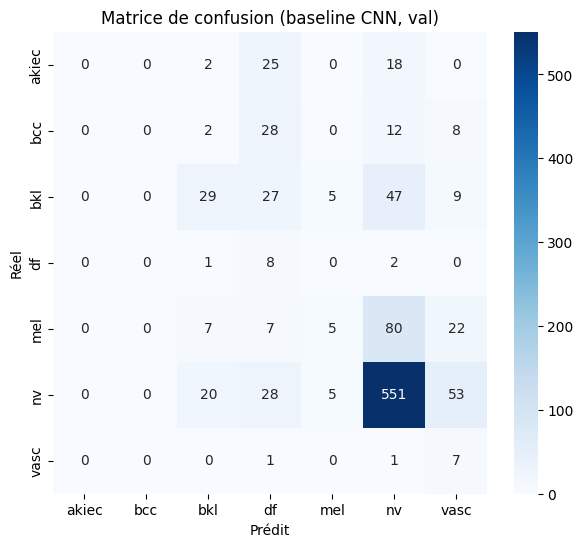

In [5]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

y_true = np.concatenate([y.numpy() for _, y in val_ds])
y_pred = np.argmax(model.predict(val_ds), axis=1)

print(classification_report(y_true, y_pred, target_names=CLASSES, digits=3))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel("Prédit")
plt.ylabel("Réel")
plt.title("Matrice de confusion (baseline CNN, val)")
plt.show()

In [7]:
model.save("cnn_scratch.keras")

from google.colab import files
files.download("cnn_scratch.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>